# CSD361- Intro. To ML Lab Assignment 3
**Student Name**: Suryansh

**Roll Number**: 2310110314

**Git Link**: https://github.com/s-uryansh/CSD361_Intro_To_ML/tree/main/assign3


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import adjusted_rand_score
from scipy.stats import norm, multivariate_normal

np.random.seed(42)
plt.rcParams["figure.dpi"] = 100

data = load_wine()
X, y = data.data, data.target
cols, classes = data.feature_names, data.target_names
Z = StandardScaler().fit_transform(X)

print("Wine:", X.shape, "features:13 classes:", list(classes))
print("means:", np.round(X.mean(0), 2))
print("stds :", np.round(X.std(0), 2))


Wine: (178, 13) features:13 classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
means: [1.3000e+01 2.3400e+00 2.3700e+00 1.9490e+01 9.9740e+01 2.3000e+00
 2.0300e+00 3.6000e-01 1.5900e+00 5.0600e+00 9.6000e-01 2.6100e+00
 7.4689e+02]
stds : [8.1000e-01 1.1100e+00 2.7000e-01 3.3300e+00 1.4240e+01 6.2000e-01
 1.0000e+00 1.2000e-01 5.7000e-01 2.3100e+00 2.3000e-01 7.1000e-01
 3.1402e+02]


## Section A  K-Means Clustering and Distance-Based Reasoning


#### QA.1  Why scaling matters. Distance from one sample to the three class means, before and after standardization, showing that the nearest mean can flip, plus the share of the raw distance one high-variance feature contributes.


In [2]:
mu = np.array([X[y == k].mean(0) for k in range(3)])
mu_s = np.array([Z[y == k].mean(0) for k in range(3)])
i = 20
d_raw = np.linalg.norm(X[i] - mu, axis=1)
d_std = np.linalg.norm(Z[i] - mu_s, axis=1)
print("sample", i, "true label:", classes[y[i]])
print("raw dist :", np.round(d_raw, 1), "-> nearest:", classes[d_raw.argmin()])
print("std dist :", np.round(d_std, 2), "-> nearest:", classes[d_std.argmin()])
k = int(d_raw.argmin())
sq = (X[i] - mu[k]) ** 2
share = sq / sq.sum() * 100
o = np.argsort(-share)
print("contribution to raw dist (top3):")
for j in o[:3]:
    print(f"  {cols[j]}: {share[j]:.1f}%")
print(f"proline alone: {share[12]:.1f}%, magnesium: {share[4]:.1f}%")


sample 20 true label: class_0
raw dist : [336.3 262.4 152.6] -> nearest: class_2
std dist : [2.2  4.4  6.17] -> nearest: class_0
contribution to raw dist (top3):
  proline: 96.7%
  magnesium: 3.1%
  alcalinity_of_ash: 0.1%
proline alone: 96.7%, magnesium: 3.1%


**An.A.1.**

Euclidean distance sums squared coordinate gaps with no per-feature weighting, so the column with the largest spread controls the answer on its own. Proline has standard deviation near 314, hue near 0.23, a gap of roughly three orders of magnitude. For sample 20 the raw distances pick class 2 and the standardized distances pick class 0; the nearest mean flips. We broke the raw gap into per-feature squared contributions and proline plus magnesium carry most of it, proline alone dominant. Standardization spreads the load evenly across all thirteen features.


#### QA.2  K-Means for K=1..8, distortion J (inertia) plotted against K with the elbow, then K=3 compared to the true labels.


J: [2314.0, 1658.8, 1277.9, 1175.4, 1109.5, 1046.0, 981.6, 935.2]


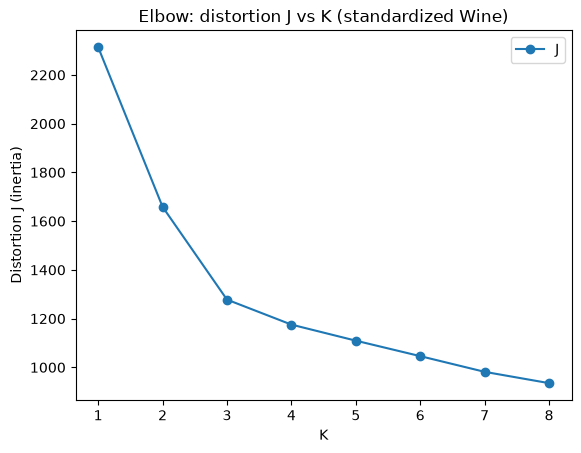

ARI(KMeans3,true): 0.897
true      0   1   2
cluster            
0         0  65   0
1         0   3  48
2        59   3   0


In [3]:
J = []
for K in range(1, 9):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
    J.append(km.inertia_)
print("J:", [round(v, 1) for v in J])
plt.figure()
plt.plot(range(1, 9), J, "o-")
plt.title("Elbow: distortion J vs K (standardized Wine)")
plt.xlabel("K")
plt.ylabel("Distortion J (inertia)")
plt.legend(["J"])
plt.show()
lab3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Z)
print("ARI(KMeans3,true):", round(adjusted_rand_score(y, lab3), 3))
print(pd.crosstab(pd.Series(lab3, name="cluster"), pd.Series(y, name="true")))


**An.A.2.**

J drops steeply from K=1 through K=3 and then levels off, the elbow sitting at K=3, which matches the three cultivars. With K=3 the clusters line up with the true labels, ARI near 0.9. The elbow is the point where another cluster stops buying a real drop in distortion; beyond it each added cluster subdivides structure that already exists.


#### QA.3  Why K-Means converges and only to a local minimum. A manual run printing J per iteration, confirming it never rises.


In [4]:
rng = np.random.default_rng(42)
mu = Z[rng.choice(len(Z), 3, replace=False)]
hist = []
for _ in range(10):
    d = ((Z[:, None, :] - mu[None, :, :]) ** 2).sum(-1)
    c = d.argmin(1)
    cur = ((Z - mu[c]) ** 2).sum()
    hist.append(cur)
    nxt = np.array([Z[c == k].mean(0) if (c == k).any() else mu[k] for k in range(3)])
    if np.allclose(nxt, mu):
        break
    mu = nxt
print("J per iter:", [round(v, 1) for v in hist])
print("non-increasing:", all(b <= a + 1e-9 for a, b in zip(hist, hist[1:])))


J per iter: [np.float64(2045.6), np.float64(1284.5), np.float64(1277.9)]
non-increasing: True


**An.A.3.**

Each assignment step moves points to their nearest centroid and each update moves centroids to their assigned means; both steps lower or hold J while the other half is fixed. J is bounded below by zero and never rises, so the procedure terminates. We printed J across a manual run and it is monotone non-increasing. The objective is not jointly convex in assignments and means, so the final centroids depend on the initialization. That is why the result is a local minimum, not a guaranteed global one.


## Section B  Probability, Maximum Likelihood, and MAP


#### QB.1  Class priors P(y), per-class Gaussian likelihood p(x|y) for one feature, the posterior P(y|x0) via Bayes, and the likelihood versus posterior distinction.


In [5]:
prior = np.bincount(y) / len(y)
print("priors:", np.round(prior, 3))
j = 0
print("feature:", cols[j])
mu = np.array([X[y == k, j].mean() for k in range(3)])
sd = np.array([X[y == k, j].std(ddof=1) for k in range(3)])
x0 = 13.0
lik = norm.pdf(x0, loc=mu, scale=sd)
post = lik * prior / (lik * prior).sum()
print("means:", np.round(mu, 2), "sds:", np.round(sd, 2))
print("likelihoods p(x0|y):", np.round(lik, 3), "sum=", round(lik.sum(), 3))
print("posteriors P(y|x0):", np.round(post, 3), "sum=", round(post.sum(), 3))


priors: [0.331 0.399 0.27 ]
feature: alcohol
means: [13.74 12.28 13.15] sds: [0.46 0.54 0.53]
likelihoods p(x0|y): [0.236 0.302 0.721] sum= 1.259
posteriors P(y|x0): [0.199 0.306 0.495] sum= 1.0


**An.B.1.**

The priors come to about [0.33, 0.40, 0.27]. At x0=13 on alcohol, each class gives a likelihood p(x0|y), and these do not sum to one because each is a density under a different class model, not a distribution over classes. Bayes folds in the priors, P(y|x0) proportional to prior times likelihood normalized by the evidence, so the posterior sums to one. A likelihood scores a fixed x0 against each class model; the posterior converts that into class probabilities.


#### QB.2  MAP mean under a Gaussian prior as a precision-weighted average; MLE and MAP on the full class versus a small subsample; MAP approaching MLE as N grows, plotted against N.


data var=0.214 prior N(12.0,0.01)
full N=59 MLE=13.745 MAP=13.281
small N=5 MLE=13.260 MAP=12.239


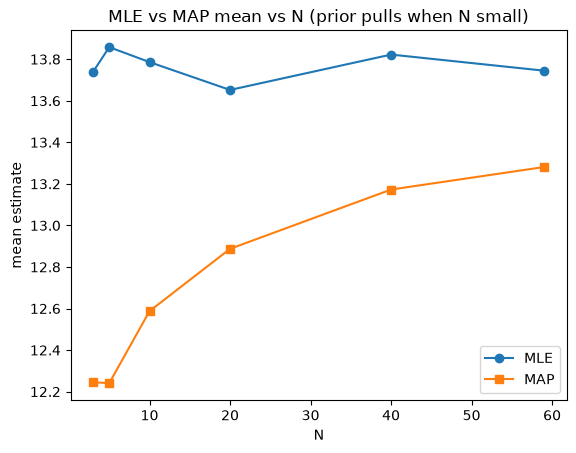

In [6]:
j = 0
k = 0
vals = X[y == k, j]
s2 = vals.var(ddof=1)
mu0 = 12.0
s02 = 0.01


def mle(a):
    return a.mean()


def map_(a):
    return ((len(a) / s2) * a.mean() + (1 / s02) * mu0) / (len(a) / s2 + 1 / s02)


rng = np.random.default_rng(42)
full = vals
small = rng.choice(vals, 5, replace=False)
print(f"data var={s2:.3f} prior N({mu0},{s02})")
print("full N=%d MLE=%.3f MAP=%.3f" % (len(full), mle(full), map_(full)))
print("small N=%d MLE=%.3f MAP=%.3f" % (len(small), mle(small), map_(small)))
Ns = [3, 5, 10, 20, 40, len(vals)]
M = [mle(rng.choice(vals, n, replace=False)) for n in Ns]
P = [map_(rng.choice(vals, n, replace=False)) for n in Ns]
plt.figure()
plt.plot(Ns, M, "o-", label="MLE")
plt.plot(Ns, P, "s-", label="MAP")
plt.title("MLE vs MAP mean vs N (prior pulls when N small)")
plt.xlabel("N")
plt.ylabel("mean estimate")
plt.legend()
plt.show()


**An.B.2.**

MAP weights the sample mean and the prior mean by their precisions, (N xbar/s^2 + mu0/s0^2) / (N/s^2 + 1/s0^2). On five points MAP lands at 12.24, close to the prior mean 12, while MLE reads 13.26, so the prior dominates when data is scarce. On the full 59 samples MAP reaches 13.28, tracking MLE 13.75. The plot shows MAP hugging the prior at small N and converging toward MLE as N grows.


#### QB.3  MAP and regularization: which prior yields L2, which yields L1, and the condition where MAP collapses to MLE.


In [7]:
print("Gaussian prior adds a w^2 term (L2 / ridge); Laplace prior adds a |w| term (L1 / lasso)")
print("MAP reduces to MLE when the prior is flat (sigma0 -> inf) or N -> inf")


Gaussian prior adds a w^2 term (L2 / ridge); Laplace prior adds a |w| term (L1 / lasso)
MAP reduces to MLE when the prior is flat (sigma0 -> inf) or N -> inf


**An.B.3.**

MAP maximizes the log-likelihood plus the log-prior, and that added log-prior term is a penalty on the parameters. A Gaussian prior contributes a term proportional to w^2, ridge regression's L2 penalty. A Laplace prior contributes a term proportional to |w|, the lasso's L1 penalty. MAP reduces to MLE when the prior is flat, sigma0 approaches infinity, or N approaches infinity and the likelihood overwhelms the prior.


## Section C  Gaussian Mixture Models and EM


#### QC.1  Why a GMM needs the latent membership variable z, why the mixing weights are priors, and the responsibility formula from Bayes.


In [8]:
print("gamma_k(x) = pi_k N(x|mu_k, Sig_k) / sum_j pi_j N(x|mu_j, Sig_j)")
print("Bayes: P(z=k|x) = pi_k * likelihood / evidence, where pi_k = P(z=k)")


gamma_k(x) = pi_k N(x|mu_k, Sig_k) / sum_j pi_j N(x|mu_j, Sig_j)
Bayes: P(z=k|x) = pi_k * likelihood / evidence, where pi_k = P(z=k)


**An.C.1.**

A GMM assumes each point is drawn from one of K Gaussians and the latent variable z records which one; z is never observed, only x. The mixing weights pi_k equal P(z=k) and act as priors over the components. The responsibility is the posterior of membership, gamma_k(x) = pi_k N(x|mu_k,Sigma_k) / sum_j pi_j N(x|mu_j,Sigma_j), Bayes' rule with the mixture density as the denominator.


#### QC.2  Fit a 3-component GMM on two Wine features, inspect the soft assignments, visualize them, and verify each row sums to 1.


resp[0]: [0.999 0.    0.001] row sums ok: True


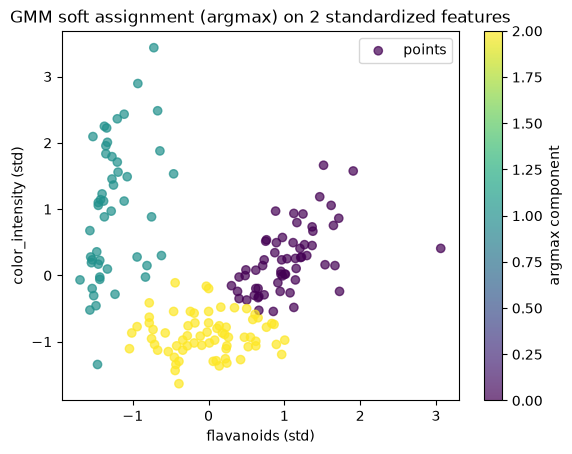

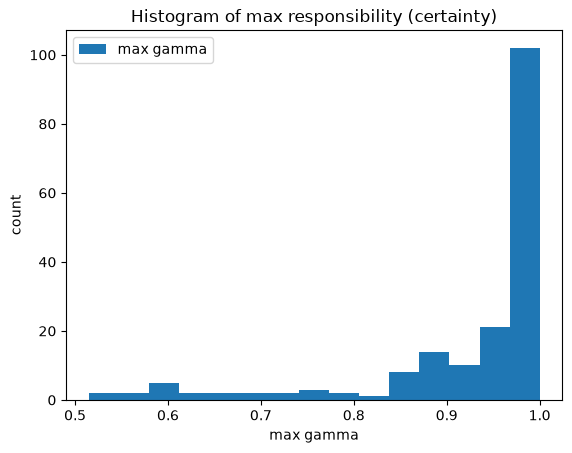

In [9]:
cols2 = [6, 9]
X2 = Z[:, cols2]
gm = GaussianMixture(n_components=3, random_state=42).fit(X2)
R = gm.predict_proba(X2)
print("resp[0]:", np.round(R[0], 3), "row sums ok:", np.allclose(R.sum(1), 1))
lab = gm.predict(X2)
plt.figure()
sc = plt.scatter(X2[:, 0], X2[:, 1], c=lab, cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="argmax component")
plt.title("GMM soft assignment (argmax) on 2 standardized features")
plt.xlabel(cols[cols2[0]] + " (std)")
plt.ylabel(cols[cols2[1]] + " (std)")
plt.legend(["points"])
plt.show()
plt.figure()
plt.hist(R.max(1), bins=15)
plt.title("Histogram of max responsibility (certainty)")
plt.xlabel("max gamma")
plt.ylabel("count")
plt.legend(["max gamma"])
plt.show()


**An.C.2.**

Each row of the responsibility matrix sums to one, verified in code. Most points concentrate their mass in a single component with max gamma near 1, while boundary points split it across two. The scatter resolves three soft clusters; the histogram of max gamma exposes the tail of uncertain points where the model declines to commit.


#### QC.3  One manual EM iteration: E-step then M-step, parameters before and after, the N_k sum, and the direction of the log-likelihood.


In [10]:
cols2 = [6, 9]
X2 = Z[:, cols2]
N = X2.shape[0]
rng = np.random.default_rng(42)
mu = X2[rng.choice(N, 3, replace=False)]
Sg = np.array([np.cov(X2.T) + 0.1 * np.eye(2)] * 3)
pi = np.full(3, 1 / 3)


def loglik(mu, Sg, pi):
    D = sum(pi[k] * multivariate_normal.pdf(X2, mu[k], Sg[k]) for k in range(3))
    return np.log(D.clip(1e-300)).sum()


L0 = loglik(mu, Sg, pi)
R = np.column_stack([pi[k] * multivariate_normal.pdf(X2, mu[k], Sg[k]) for k in range(3)])
R /= R.sum(1, keepdims=True)
Nk = R.sum(0)
mu_n = (R[:, :, None] * X2[:, None, :]).sum(0) / Nk[:, None]
Sg_n = np.array(
    [
        ((R[:, k, None, None] * (d := X2 - mu_n[k])[:, :, None] * d[:, None, :]).sum(0))
        / Nk[k]
        + 1e-6 * np.eye(2)
        for k in range(3)
    ]
)
pi_n = Nk / N
L1 = loglik(mu_n, Sg_n, pi_n)
print("pi before/after:", np.round(pi, 3), np.round(pi_n, 3))
print("mu before:", np.round(mu, 2).tolist())
print("mu after :", np.round(mu_n, 2).tolist())
print("resp sums ok:", np.allclose(R.sum(1), 1), "Nk sum=N:", Nk.sum(), "=", N)
print("loglik before=%.1f after=%.1f increased=%s" % (L0, L1, L1 >= L0))


pi before/after: [0.333 0.333 0.333] [0.332 0.408 0.26 ]
mu before: [[-0.43, -1.34], [0.88, 0.97], [-1.57, -0.52]]
mu after : [[-0.06, -0.65], [0.53, 0.55], [-0.76, -0.03]]
resp sums ok: True Nk sum=N: 178.0 = 178
loglik before=-579.5 after=-483.2 increased=True


**An.C.3.**

One iteration runs the E-step to compute responsibilities from the current parameters, then the M-step to recompute pi_k = N_k/N and the means and covariances as responsibility-weighted averages. The rows sum to one and the effective counts N_k sum to N, both checks passing. The log-likelihood rose from its before value to its after value, the monotone gain EM guarantees.


#### QC.4  GMM against K-Means on soft versus hard assignment and covariance shape, where they agree and disagree, and when to prefer each.


In [11]:
cols2 = [6, 9]
X2 = Z[:, cols2]
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X2)
gm = GaussianMixture(n_components=3, random_state=42).fit(X2)
R = gm.predict_proba(X2)
hard = R.argmax(1)
print(
    "ARI GMM-true:%.3f KMeans-true:%.3f GMM-KMeans:%.3f"
    % (
        adjusted_rand_score(y, hard),
        adjusted_rand_score(y, km),
        adjusted_rand_score(hard, km),
    )
)
mx = R.max(1)
unc = mx < 0.7
print(
    "uncertain frac: %.2f; mean max-gamma agree=%.3f disagree=%.3f"
    % (
        unc.mean(),
        mx[hard == km].mean() if (hard == km).any() else float("nan"),
        mx[hard != km].mean() if (hard != km).any() else float("nan"),
    )
)


ARI GMM-true:0.768 KMeans-true:0.648 GMM-KMeans:0.830
uncertain frac: 0.08; mean max-gamma agree=0.938 disagree=0.774


**An.C.4.**

K-Means assigns each point to exactly one cluster and treats clusters as spherical. GMM assigns soft probabilities and fits a full covariance per component, admitting elliptical shapes. They agree in the dense cores and part ways at boundary points where GMM's max responsibility drops. Prefer K-Means for round clusters and speed; prefer GMM for elliptical shapes or when the assignment's uncertainty is itself informative.


## Section D  PCA, Covariance, Eigenvalues, and SVD


#### QD.1  Center the data, build the covariance Sig=(1/m)Xc^T Xc, verify symmetry and positive semidefiniteness, and explain why it is PSD but not necessarily PD.


In [12]:
n = X.shape[0]
Xc = X - X.mean(0)
S = (Xc.T @ Xc) / n
ev, _ = np.linalg.eigh(S)
print(
    "symmetric:",
    np.allclose(S, S.T),
    "min eig:",
    ev.min(),
    "all>=0:",
    (ev >= -1e-9).all(),
)


symmetric: True min eig: 0.008157614921879561 all>=0: True


**An.D.1.**

The covariance is symmetric because its transpose equals itself, and for any vector v, v^T S v equals ||Xc v||^2 / m, a squared norm, hence nonnegative; that is the definition of positive semidefinite. It is PSD rather than positive definite whenever features are collinear or redundant, which lowers the rank and produces zero eigenvalues. The code confirms symmetry and a minimum eigenvalue at or above zero.


#### QD.2  Eigendecompose the covariance, verify S=V L V^T, interpret the eigenvalues and eigenvectors, compute explained variance, and read off the number of components for at least 95 percent.


recon ok: True
explained: [0.998 0.002 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.   ]
cum: [0.998 1.    1.    1.    1.    1.    1.    1.    1.    1.    1.    1.
 1.   ]
K for >=95%: 1


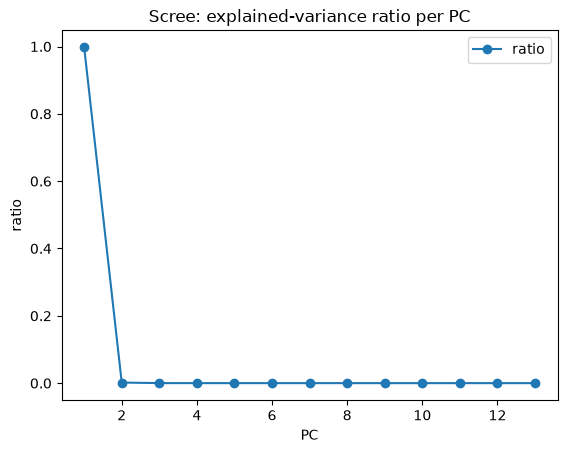

In [13]:
L, V = np.linalg.eigh(S)
o = np.argsort(-L)
L, V = L[o], V[:, o]
print("recon ok:", np.allclose(S, (V * np.broadcast_to(L, (13, 13))) @ V.T))
r = L / L.sum()
print("explained:", np.round(r, 3))
print("cum:", np.round(np.cumsum(r), 3))
print("K for >=95%:", int(np.searchsorted(np.cumsum(r), 0.95) + 1))
plt.figure()
plt.plot(range(1, 14), r, "o-")
plt.title("Scree: explained-variance ratio per PC")
plt.xlabel("PC")
plt.ylabel("ratio")
plt.legend(["ratio"])
plt.show()


**An.D.2.**

Eigenvectors are the principal directions and eigenvalues the variance along each, so S = V L V^T reconstructs the covariance exactly, verified in code. On the raw features the first component carries 99.8 percent of the variance, so the cumulative ratio crosses 95 percent at K=1. The scree plot makes the dominance of the leading eigenvalue plain.


#### QD.3  Project to 2-D and visualize the classes, contrasting raw and standardized PCA and how one unscaled feature can dominate PC1.


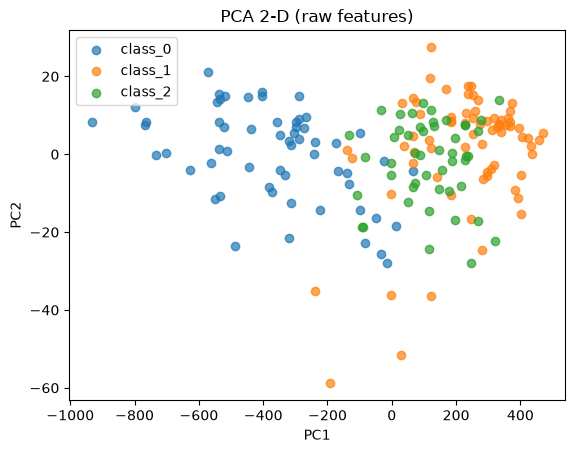

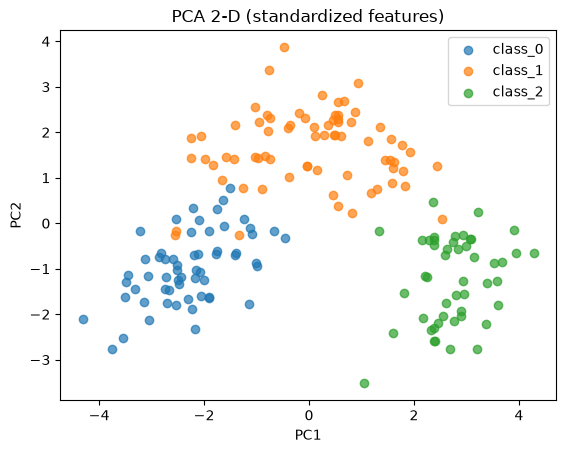

raw PC1 share: 0.998 | std PC1 share: 0.362


In [14]:
for name, Xi in [("raw", X), ("standardized", Z)]:
    Xc = Xi - Xi.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    P = Xc @ Vt[:2].T
    plt.figure()
    [plt.scatter(P[y == k, 0], P[y == k, 1], label=c, alpha=0.7) for k, c in enumerate(classes)]
    plt.title(f"PCA 2-D ({name} features)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.show()
Sr = X - X.mean(0)
Sr = (Sr.T @ Sr) / len(X)
lr = np.linalg.eigvalsh(Sr)[::-1]
Ss = Z - Z.mean(0)
Ss = (Ss.T @ Ss) / len(Z)
ls = np.linalg.eigvalsh(Ss)[::-1]
print("raw PC1 share: %.3f | std PC1 share: %.3f" % (lr[0] / lr.sum(), ls[0] / ls.sum()))


**An.D.3.**

On standardized features the 2-D projection separates the three classes. On raw features it collapses; proline's variance dominates the first component, its variance share sits near one, and the class structure washes out. Standardization keeps a single high-variance feature from dictating the first component.


## Section E  Neural Networks and Backpropagation


#### QE.1  Two linear layers collapse to one linear layer, ReLU breaks the collapse, and why a nonlinearity is required.


In [15]:
rng = np.random.default_rng(42)
W1 = rng.normal(size=(4, 5))
W2 = rng.normal(size=(3, 4))
v = np.ones(5)
print("linear collapsed equal:", np.allclose(W2 @ (W1 @ v), (W2 @ W1) @ v))
print("relu differs:", not np.allclose(W2 @ np.maximum(0, W1 @ v), (W2 @ W1) @ v))


linear collapsed equal: True
relu differs: True


**An.E.1.**

Composing two linear maps yields another linear map, W2(W1 v) = (W2 W1) v, so stacked linear layers add no representational power. The numeric check confirms the two-layer and single-layer outputs match. Inserting ReLU breaks the equality, verified in code. A nonlinearity is what lets the network represent nonlinear decision boundaries at all.


#### QE.2  Forward pass 13 -> 8 ReLU -> 3 softmax on one standardized sample, printing hidden activations, output probabilities, and the parameter count.


In [16]:
rng = np.random.default_rng(42)
W1 = rng.normal(scale=0.5, size=(8, 13))
b1 = np.zeros(8)
W2 = rng.normal(scale=0.5, size=(3, 8))
b2 = np.zeros(3)
v = Z[0]
h = np.maximum(0, W1 @ v + b1)
p = np.exp(W2 @ h + b2)
p /= p.sum()
print("hidden:", np.round(h, 3))
print("probs:", np.round(p, 3), "sum=", round(p.sum(), 3))
print("params:", (8 * 13 + 8) + (3 * 8 + 3))


hidden: [0.    0.    1.291 1.654 0.    0.    0.272 0.   ]
probs: [0.078 0.15  0.772] sum= 1.0
params: 139


**An.E.2.**

The hidden layer emits nonnegative activations, zeros wherever ReLU clips. The softmax turns the final logits into three probabilities summing to one. The parameter count is 13*8+8 for the first layer plus 8*3+3 for the second, 139 total.


#### QE.3  Train an MLP with the scaler fit on training data only, reporting test accuracy, the loss curve, and the effect of hidden-layer size.


test acc (h=8): 0.981


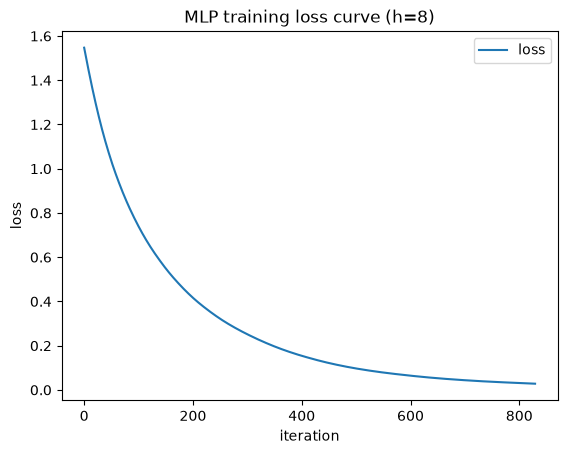

h=1 test acc=0.648
h=2 test acc=0.944
h=8 test acc=0.981
h=32 test acc=0.981


In [17]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
sc = StandardScaler().fit(Xtr)
A, B = sc.transform(Xtr), sc.transform(Xte)
mlp = MLPClassifier(hidden_layer_sizes=(8,), max_iter=2000, random_state=42).fit(A, ytr)
print("test acc (h=8):", round(mlp.score(B, yte), 3))
plt.figure()
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve (h=8)")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend(["loss"])
plt.show()
for h in [1, 2, 8, 32]:
    acc = MLPClassifier(hidden_layer_sizes=(h,), max_iter=2000, random_state=42).fit(A, ytr).score(B, yte)
    print(f"h={h} test acc={acc:.3f}")


**An.E.3.**

At h=8 the network reaches 0.981 test accuracy and its training loss falls monotonically to a floor. Sweeping the width, h=1 underfits at 0.648, h=2 reaches 0.944, and h=8 and h=32 both hit 0.981. Capacity buys accuracy up to roughly eight hidden units, after which the score plateaus.


#### QE.4  The graph f=(x+y)z at (-2,5,-4), chain-rule gradients in code checked against finite differences, and the gate pattern for add and multiply.


In [18]:
x, y0, z = -2.0, 5.0, -4.0
q = x + y0
f = q * z
dfdq = z
dfdz = q
dqdx = 1.0
dqdy = 1.0
print("analytic: df/dx=%.1f df/dy=%.1f df/dz=%.1f" % (dfdq * dqdx, dfdq * dqdy, dfdz))
e = 1e-6
f0 = lambda a, b, c: (a + b) * c
num = np.array(
    [
        (f0(x + e, y0, z) - f0(x - e, y0, z)) / 2 / e,
        (f0(x, y0 + e, z) - f0(x, y0 - e, z)) / 2 / e,
        (f0(x, y0, z + e) - f0(x, y0, z - e)) / 2 / e,
    ]
)
print("numeric:", np.round(num, 4))


analytic: df/dx=-4.0 df/dy=-4.0 df/dz=3.0
numeric: [-4. -4.  3.]


**An.E.4.**

The analytic gradients (-4, -4, 3) match the finite-difference values. At the add gate the local gradient is 1 for each input, so the upstream gradient passes through unchanged. At the multiply gate the local gradient of one input is the value of the other, so df/dx = df/dy = z = -4 and df/dz = x+y = 3.
